# Algebra with Vulkan Profiles

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler

from src.utils import fs_utils
from src.vulkan_math_data import (
    attach_catalog_and_benchmarks,
    feature_matrix,
    load_vulkan_feature_frame,
)

project_root, data_dir = fs_utils.get_data_dir()
sns.set_theme(context="notebook", style="whitegrid")
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)
project_root, data_dir

(PosixPath('/opt/pc-hardware-analysis'),
 PosixPath('/opt/pc-hardware-analysis/data'))

In [ ]:
vulkan_frame = load_vulkan_feature_frame(data_dir / "vulkan-profiles")
joined_frame, diagnostics = attach_catalog_and_benchmarks(vulkan_frame)
matrix, matrix_columns = feature_matrix(joined_frame)

print("Rows:", len(joined_frame))
print("Raw columns:", len(joined_frame.columns))
print("Modeling columns after constant-column removal:", len(matrix_columns))
print("Catalog matches:", diagnostics["catalog_matches"])
print("Benchmark matches:", diagnostics["benchmark_matches"])
display(
    joined_frame[
        [
            "report_id",
            "profile_label",
            "normalized_gpu_name",
            "vendor_name",
            "catalog_model",
            "model",
            "benchmark",
        ]
    ]
)

In [ ]:
summary = pd.DataFrame(
    {
        "feature": matrix_columns[:20],
        "nonzero_fraction": [
            (matrix[column] != 0).mean() for column in matrix_columns[:20]
        ],
        "mean": [matrix[column].mean() for column in matrix_columns[:20]],
        "std": [matrix[column].std() for column in matrix_columns[:20]],
    }
)
display(summary)

if matrix.shape[1] > 1:
    plt.figure(figsize=(10, 4))
    summary.plot.bar(
        x="feature", y="nonzero_fraction", legend=False, rot=75, figsize=(12, 4)
    )
    plt.title("Non-zero fraction for the first modeled features")
    plt.tight_layout()
    plt.show()

,subgroupSize
0,32
1,32
2,32
3,32
4,32
...,...
261,32
262,32
263,32
264,32


,feature,nonzero_fraction,mean,std
0,subgroupSize,1.0,34.646617,8.830646


In [ ]:
scaled = StandardScaler().fit_transform(matrix)
max_components = min(2, scaled.shape[0], scaled.shape[1])
if max_components >= 1:
    pca = PCA(n_components=max_components)
    embedding = pca.fit_transform(scaled)
    pca_frame = pd.DataFrame(
        embedding, columns=[f"pc{i + 1}" for i in range(max_components)]
    )
    pca_frame.insert(0, "report_id", vulkan_frame["report_id"].to_list())
    display(pca_frame)
    print("Explained variance ratio:", pca.explained_variance_ratio_)

    if max_components == 2:
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=pca_frame, x="pc1", y="pc2", hue="label", s=120)
        for _, row in pca_frame.iterrows():
            plt.text(row["pc1"], row["pc2"], row["report_id"])
        plt.title("PCA embedding of Vulkan profile feature rows")
        plt.tight_layout()
        plt.show()

,report_id,pc1
0,10934,-0.300273
1,10993,-0.300273
2,11121,-0.300273
3,11141,-0.300273
4,11209,-0.300273
...,...,...
261,49142,-0.300273
262,49144,-0.300273
263,49180,-0.300273
264,49185,-0.300273


Explained variance ratio: [1.]


report_id,10934,10993,11121,11141,11209,11309,...,49130,49142,49144,49180,49185,49229
report_id,,,,,,,,,,,,,
10934,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0
10993,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0
11121,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0
11141,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0
11209,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49142,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0
49144,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0
49180,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0


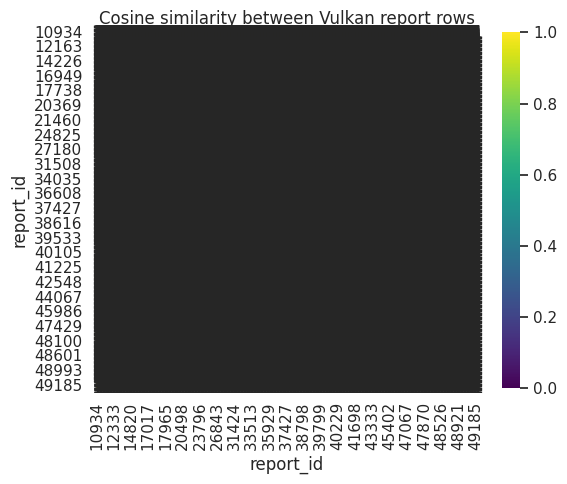

In [19]:
similarity = pd.DataFrame(
    cosine_similarity(matrix),
    index=vulkan_frame["report_id"],
    columns=vulkan_frame["report_id"],
)
display(similarity)

plt.figure(figsize=(6, 5))
sns.heatmap(similarity, annot=True, cmap="viridis", vmin=0, vmax=1)
plt.title("Cosine similarity between Vulkan report rows")
plt.tight_layout()
plt.show()

In [23]:
if len(matrix) >= 2:
    cluster_count = min(2, len(matrix))
    clustering = KMeans(n_clusters=cluster_count, n_init=10, random_state=7)
    joined_frame["cluster_id"] = clustering.fit_predict(matrix)
    display(joined_frame[["report_id", "normalized_gpu_name", "cluster_id"]])
else:
    print("Clustering skipped because fewer than two rows are available.")

,report_id,normalized_gpu_name,cluster_id
0,36677,rtx 5090,1
1,38066,rtx 5090,1
2,38358,rtx 5090,1
3,38575,radeon rx 9070 xt,0
4,38847,rtx 5090,1
5,38914,rtx 5090,0
6,39783,rtx 5090,0
7,40081,rtx 5060,1
8,40105,rtx 5070,0
9,40415,radeon rx 9070 xt,0
